# Datos de e-commerce (impresora 3D)

 Este data set contiene datos del producto impresora 3D de la pagina de Ebay 
 
 Los datos fueron obtenidos por scraping utilizando la siguiente plataforma
 https://scrapebadger.com/dashboard/ebay-scraper


 ## ETL

### EXTRACT
Los datos inicialmente se extrajeron en un formato JSON por lo cual se convirtio a formato CSV, se encuentran de la siguiente manera:

In [3]:
import json
import pandas as pd

# 1. Cargar el JSON nativo
with open("data.json", "r", encoding="utf-8") as f:
    data = json.load(f)

results = data.get("results", [])
df = pd.json_normalize(results)
df.to_csv("data.csv", index=False, encoding="utf-8-sig")
df.head()

,position,item_id,product_id,title,url,image,discount_percent,currency,condition,brand,...,original_price.raw,original_price,shipping_cost.value,shipping_cost.currency,shipping_cost.symbol,shipping_cost.raw,current_bid.value,current_bid.currency,current_bid.symbol,current_bid.raw
0,1,267076111140,None,FLASHFORGE AD5X Multi-Color 3D Printer Max 600...,https://www.ebay.com/itm/267076111140,https://i.ebayimg.com/images/g/1OIAAeSwyJ5p4vL...,30.1,USD,Brand New,None,...,$499.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,317210419633,None,FLASHFORGE 3D Printer AD5X Multi-Color IFS Aut...,https://www.ebay.com/itm/317210419633,https://i.ebayimg.com/images/g/pX0AAeSwkDRqJ-C...,30.1,USD,Brand New,None,...,$499.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,157211704935,None,FLASHFORGE AD5X Upgraded Multi-Color 3D Printe...,https://www.ebay.com/itm/157211704935,https://i.ebayimg.com/images/g/3MAAAeSw3gJop8c...,30.1,USD,Brand New,None,...,$499.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,155956155406,None,FLASHFORGE 3D Printer Adventurer 5M Core XY St...,https://www.ebay.com/itm/155956155406,https://i.ebayimg.com/images/g/n8AAAOSwnIxlf7O...,37.6,USD,Brand New,None,...,$399.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,304831249555,None,impresora 3D con placa de superficie extraíble...,https://www.ebay.com/itm/304831249555,https://i.ebayimg.com/images/g/qPwAAOSwHVxnXuX...,5.0,USD,Brand New,None,...,$434.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


vemos datos relevantes del DataFrame:

In [23]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   position                 122 non-null    int64  
 1   item_id                  122 non-null    int64  
 2   title                    122 non-null    object 
 3   url                      122 non-null    object 
 4   image                    122 non-null    object 
 5   currency                 122 non-null    object 
 6   condition                122 non-null    object 
 7   buying_format            122 non-null    object 
 8   is_auction               122 non-null    bool   
 9   shipping                 121 non-null    object 
 10  free_shipping            87 non-null     object 
 11  location                 122 non-null    object 
 12  seller_name              122 non-null    object 
 13  seller_feedback_percent  122 non-null    float64
 14  seller_feedback_score    1

,position,item_id,seller_feedback_percent,seller_feedback_score,price.value
count,122.000000,1.220000e+02,122.000000,122.000000,122.000000
mean,61.500000,2.899662e+11,95.194262,47553.991803,289.019262
std,35.362409,1.919986e+11,19.774503,109398.794855,266.913609
min,1.000000,1.170491e+11,0.000000,0.000000,13.710000
25%,31.250000,1.472137e+11,98.500000,421.250000,85.572500
50%,61.500000,2.467652e+11,99.100000,9000.000000,234.175000
75%,91.750000,3.649051e+11,100.000000,71000.000000,398.937500
max,122.000000,9.600281e+11,100.000000,510000.000000,1500.000000


### TRANSFORMATION

La siguiente tabla muestra las columnas junto a la cantidad de datos nulos que contienen:

In [4]:


df = pd.read_csv("data.csv")
nulos = df.isnull().sum()
resumen_nulos = nulos[nulos > 0].sort_values(ascending=False)
print(resumen_nulos)


current_bid                122
exact_match                122
shipping_cost              122
sold_date                  122
sold_date_at               122
is_sponsored               122
original_price             122
current_bid.raw            121
time_left                  121
bids                       121
current_bid.symbol         121
current_bid.currency       121
current_bid.value          121
product_id                 120
ratings_total              120
rating                     120
brand                      118
original_price.currency    102
original_price.raw         102
original_price.symbol      102
original_price.value       102
watchers                   102
discount_percent           102
sold_count                  96
program_badge               90
shipping_cost.raw           88
shipping_cost.symbol        88
shipping_cost.currency      88
shipping_cost.value         88
coupon                      82
returns                     77
free_shipping               35
shipping

Se procedio a eliminar las columnas que contienen mayor cantidad de datos nulos:

In [ ]:
import pandas as pd

df = pd.read_csv("data.csv")

# LIMIEZA DE COLUMNAS QUE TIENES DATOS NULOS
# las razones datos vacios, incompletos, inecesarios
df = df.drop(columns=['current_bid'])
df = df.drop(columns=['shipping_cost'])
df = df.drop(columns=['sold_date'])
df = df.drop(columns=['sold_date_at'])
df = df.drop(columns=['is_sponsored'])
df = df.drop(columns=['exact_match'])
df = df.drop(columns=['original_price'])
df = df.drop(columns=['current_bid.value'])
df = df.drop(columns=['current_bid.currency'])
df = df.drop(columns=['current_bid.symbol'])
df = df.drop(columns=['current_bid.raw'])
df = df.drop(columns=['bids'])
df = df.drop(columns=['time_left'])
df = df.drop(columns=['ratings_total'])
df = df.drop(columns=['rating'])
df = df.drop(columns=['product_id'])
df = df.drop(columns=['brand'])
df = df.drop(columns=['discount_percent'])
df = df.drop(columns=['watchers'])
df = df.drop(columns=['original_price.currency'])
df = df.drop(columns=['original_price.value'])
df = df.drop(columns=['original_price.raw'])
df = df.drop(columns=['original_price.symbol'])
df = df.drop(columns=['sold_count'])
df = df.drop(columns=['program_badge'])
df = df.drop(columns=['shipping_cost.symbol'])
df = df.drop(columns=['shipping_cost.raw'])
df = df.drop(columns=['shipping_cost.currency'])
df = df.drop(columns=['shipping_cost.value'])
df = df.drop(columns=['coupon'])
df = df.drop(columns=['returns'])
df = df.drop(columns=['price.currency'])
df = df.drop(columns=['price.symbol'])


### LOAD

finalmente guardamos los datos en un archivo limpio en formato CSV

In [ ]:
df.to_csv("data_limpio.csv", index=False)

### Una vez realizado la limpieza y el proceso ETL

cargamos los datos CSV en un DataFrame









In [8]:
df = pd.read_csv("data_clean.csv")
df.head()

,position,item_id,title,url,image,currency,condition,buying_format,is_auction,shipping,free_shipping,location,seller_name,seller_feedback_percent,seller_feedback_score,price.value,price.raw
0,1,267076111140,FLASHFORGE AD5X Multi-Color 3D Printer Max 600...,https://www.ebay.com/itm/267076111140,https://i.ebayimg.com/images/g/1OIAAeSwyJ5p4vL...,USD,Brand New,Buy It Now,False,Free delivery,True,United States,flashforge_3d_printer,100.0,7300,349.00,$349.00
1,2,317210419633,FLASHFORGE 3D Printer AD5X Multi-Color IFS Aut...,https://www.ebay.com/itm/317210419633,https://i.ebayimg.com/images/g/pX0AAeSwkDRqJ-C...,USD,Brand New,Best Offer,False,Free delivery,True,United States,flashforge_3d_pro,99.8,5200,349.00,$349.00
2,3,157211704935,FLASHFORGE AD5X Upgraded Multi-Color 3D Printe...,https://www.ebay.com/itm/157211704935,https://i.ebayimg.com/images/g/3MAAAeSw3gJop8c...,USD,Brand New,Best Offer,False,Free delivery,True,United States,flashforge_3d_direct,99.9,2700,349.00,$349.00
3,4,155956155406,FLASHFORGE 3D Printer Adventurer 5M Core XY St...,https://www.ebay.com/itm/155956155406,https://i.ebayimg.com/images/g/n8AAAOSwnIxlf7O...,USD,Brand New,Best Offer,False,Free delivery,True,United States,flashforge_3d_direct,99.9,2700,249.00,$249.00
4,5,304831249555,impresora 3D con placa de superficie extraíble...,https://www.ebay.com/itm/304831249555,https://i.ebayimg.com/images/g/qPwAAOSwHVxnXuX...,USD,Brand New,Buy It Now,False,Free delivery,True,United States,pme-1032,99.6,869,413.24,$413.24


### Realizamos las siguientes preguntas:

In [26]:
import numpy as np

print("Precio promedio:", df["price.value"].mean())
print("Precio mediano:", df["price.value"].median())
print("Precio máximo:", df["price.value"].max())
print("Precio mínimo:", df["price.value"].min())

Precio promedio: 289.0192622950819
Precio mediano: 234.175
Precio máximo: 1500.0
Precio mínimo: 13.71


## PRODUCTO MÁS CARO y PRODUCTO MÁS BARATO

In [14]:

idx_max = df['price.value'].idxmax()
idx_min = df['price.value'].idxmin()
# Extraer los productos completos usando .loc
producto_mas_caro = df.loc[idx_max]
producto_mas_barato = df.loc[idx_min]

# Mostrar los resultados clave (por ejemplo, título y precio)
print("--- PRODUCTO MÁS CARO ---")
print(f"Título: {producto_mas_caro['title']}")
print(f"Precio: {producto_mas_caro['price.value']} {producto_mas_caro['currency']}")
print(f"URL: {producto_mas_caro['url']}\n")

print("--- PRODUCTO MÁS BARATO ---")
print(f"Título: {producto_mas_barato['title']}")
print(f"Precio: {producto_mas_barato['price.value']} {producto_mas_barato['currency']}")
print(f"URL: {producto_mas_barato['url']}")


--- PRODUCTO MÁS CARO ---
Título: 3D printer
Precio: 1500.0 USD
URL: https://www.ebay.com/itm/189057367217

--- PRODUCTO MÁS BARATO ---
Título: 3D Printer Parts End Stop Limit Module Horizontal Type
Precio: 13.71 USD
URL: https://www.ebay.com/itm/147213431744


### Grafica de top 10 vendedores con mayor puntuación
vendedores con almenos 3 productos

                seller_name  puntuacion_promedio  porcentaje_positivo  \
41          pcarena-bristol             510000.0                 98.1   
17           eurowagensltd1              71000.0                 99.1   
10     creality_refurbished              19800.0                 98.5   
9   creality-official-store              19500.0                 99.6   
1        anycubic_outlet_us               9000.0                 98.3   
23    flashforge_3d_printer               7300.0                100.0   
25      flashforge_3d_world               5400.0                100.0   
24        flashforge_3d_pro               5200.0                 99.8   
21     flashforge_3d_direct               2700.0                 99.9   

    total_productos  
41                6  
17               29  
10               10  
9                 7  
1                 7  
23                3  
25                4  
24                4  
21                3  


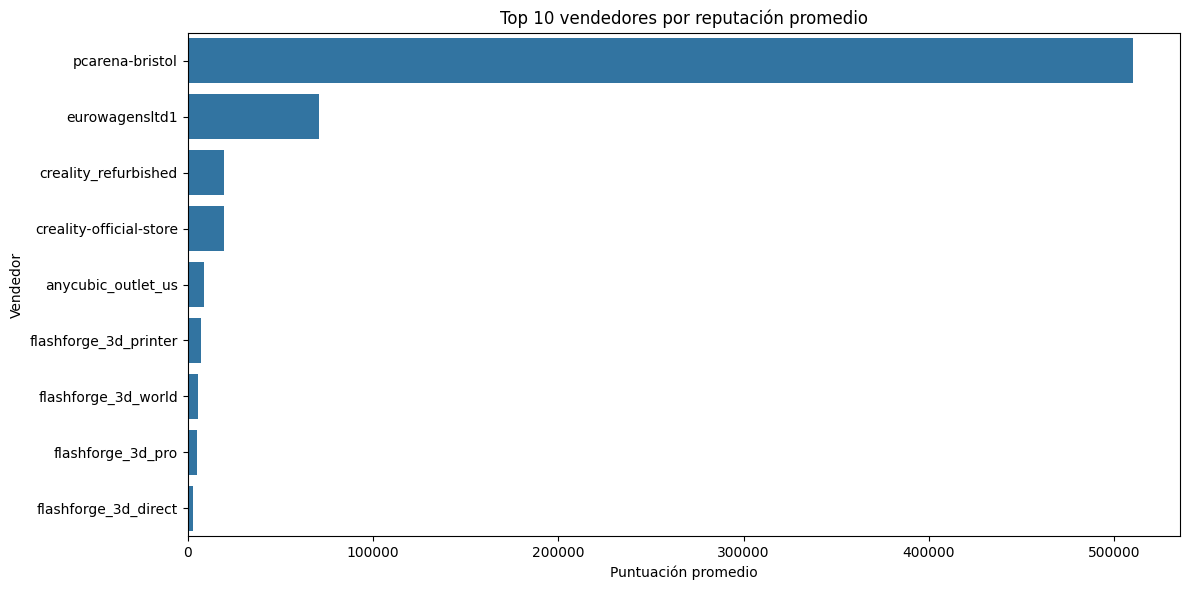

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


# Agrupar por vendedor y calcular estadísticas
ranking_vendedores = (
    df.groupby("seller_name")
    .agg(
        puntuacion_promedio=("seller_feedback_score", "mean"),
        porcentaje_positivo=("seller_feedback_percent", "mean"),
        total_productos=("item_id", "count")
    )
    .reset_index()
)

# Ordenar por puntuación promedio
ranking_vendedores = ranking_vendedores.sort_values(
    by="puntuacion_promedio",
    ascending=False
)

top_vendedores = (
    ranking_vendedores[
        ranking_vendedores["total_productos"] >= 3
    ]
    .sort_values("puntuacion_promedio", ascending=False)
    .head(10)
)

print(top_vendedores)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_vendedores,
    x="puntuacion_promedio",
    y="seller_name"
)

plt.title("Top 10 vendedores por reputación promedio")
plt.xlabel("Puntuación promedio")
plt.ylabel("Vendedor")
plt.tight_layout()
plt.show()


## Con polars


<class 'polars.dataframe.frame.DataFrame'>
shape: (2, 3)
┌───────────────┬────────────────────┬────────────┐
│ free_shipping ┆ cantidad_productos ┆ porcentaje │
│ ---           ┆ ---                ┆ ---        │
│ bool          ┆ u32                ┆ f64        │
╞═══════════════╪════════════════════╪════════════╡
│ null          ┆ 35                 ┆ 28.69      │
│ true          ┆ 87                 ┆ 71.31      │
└───────────────┴────────────────────┴────────────┘


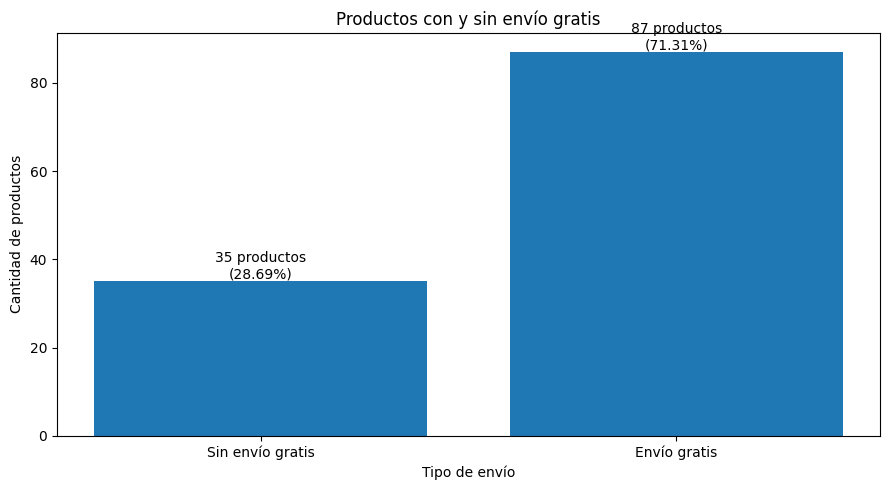

In [48]:
# Contar productos con y sin envío gratis
import polars as pl

dfp = pl.from_pandas(df)

print(type(dfp))

resultado = (
    dfp.group_by("free_shipping")
    .agg(
        pl.len().alias("cantidad_productos")
    )
    .with_columns(
        (
            pl.col("cantidad_productos")
            / pl.col("cantidad_productos").sum()
            * 100
        ).round(2).alias("porcentaje")
    )
    .sort("free_shipping", descending=True)
)

print(resultado)


# Convertir los resultados de Polars a listas
etiquetas = [
    "Envío gratis" if valor else "Sin envío gratis"
    for valor in resultado["free_shipping"].to_list()
]

cantidades = resultado["cantidad_productos"].to_list()
porcentajes = resultado["porcentaje"].to_list()

# Crear gráfico
plt.figure(figsize=(9, 5))

barras = plt.bar(etiquetas, cantidades)

# Mostrar cantidad y porcentaje sobre cada barra
for barra, cantidad, porcentaje in zip(
    barras, cantidades, porcentajes
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{cantidad} productos\n({porcentaje:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.title("Productos con y sin envío gratis")
plt.xlabel("Tipo de envío")
plt.ylabel("Cantidad de productos")
plt.tight_layout()
plt.show()

## Con Seaborn

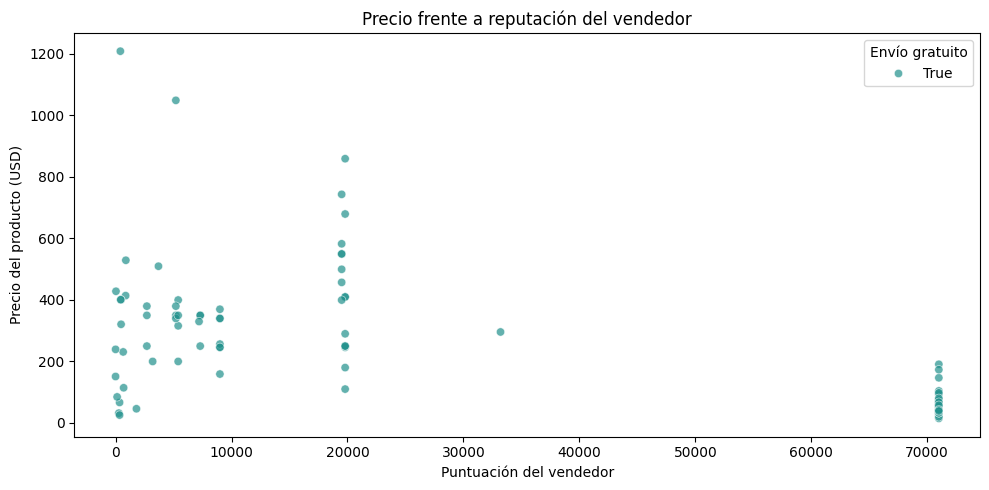

In [12]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="seller_feedback_score",
    y="price.value",
    hue="free_shipping",
    palette="viridis",
    alpha=0.7
)

plt.title("Precio frente a reputación del vendedor")
plt.xlabel("Puntuación del vendedor")
plt.ylabel("Precio del producto (USD)")
plt.legend(title="Envío gratuito")
plt.tight_layout()
plt.show()


## Grafica interactiva

In [49]:
import sweetviz as sv

reporte = sv.analyze(df)
reporte.show_html("reporte_sweetviz.html")

                                             |          | [  0%]   00:00 -> (? left)

d:\PROGRAMAS\python\Lib\site-packages\sweetviz\graph.py:67: UserWarning: Glyph 128315 (\N{DOWN-POINTING RED TRIANGLE}) missing from font(s) Roboto.
  figure.canvas.draw()
d:\PROGRAMAS\python\Lib\site-packages\sweetviz\graph.py:67: UserWarning: Glyph 9889 (\N{HIGH VOLTAGE SIGN}) missing from font(s) Roboto.
  figure.canvas.draw()
d:\PROGRAMAS\python\Lib\site-packages\sweetviz\graph.py:67: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Roboto.
  figure.canvas.draw()
d:\PROGRAMAS\python\Lib\site-packages\sweetviz\graph.py:67: UserWarning: Glyph 10084 (\N{HEAVY BLACK HEART}) missing from font(s) Roboto.
  figure.canvas.draw()
d:\PROGRAMAS\python\Lib\site-packages\sweetviz\graph.py:67: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Roboto.
  figure.canvas.draw()
d:\PROGRAMAS\python\Lib\site-packages\sweetviz\graph.py:134: UserWarning: Glyph 128315 (\N{DOWN-POINTING RED TRIANGLE}) missing from font(s) Roboto.
  figure.savefig(as_raw_bytes

Report reporte_sweetviz.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


Precio promedio: 289.02 (Desviación: 265.82)
Se encontraron 1 productos en subasta baratos.
     position       item_id  \
116       117  298741056542   

                                                 title  \
116  Monoprice Voxel 3D Printer - Fully Enclosed wi...   

                                       url  \
116  https://www.ebay.com/itm/298741056542   

                                                 image currency  condition  \
116  https://i.ebayimg.com/images/g/tyAAAeSwKwRqxpu...      USD  Pre-Owned   

    buying_format  is_auction          shipping free_shipping       location  \
116       Auction        True  +$47.26 delivery           NaN  United States   

    seller_name  seller_feedback_percent  seller_feedback_score  price.value  \
116    ma626613                    100.0                      1        180.0   

    price.raw  
116   $180.00  
--- PRODUCTO MÁS CARO ---
Título: 3D printer
Precio: 1500.0 USD
URL: https://www.ebay.com/itm/189057367217

--- PRODUCTO MÁS

C:\Users\ASUS\AppData\Local\Temp\ipykernel_14904\2436322138.py:69: UserWarning: Glyph 12304 (\N{LEFT BLACK LENTICULAR BRACKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # Asegura que no se corten los textos de los bordes
C:\Users\ASUS\AppData\Local\Temp\ipykernel_14904\2436322138.py:69: UserWarning: Glyph 12305 (\N{RIGHT BLACK LENTICULAR BRACKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # Asegura que no se corten los textos de los bordes
d:\PROGRAMAS\python\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 12304 (\N{LEFT BLACK LENTICULAR BRACKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\PROGRAMAS\python\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 12305 (\N{RIGHT BLACK LENTICULAR BRACKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


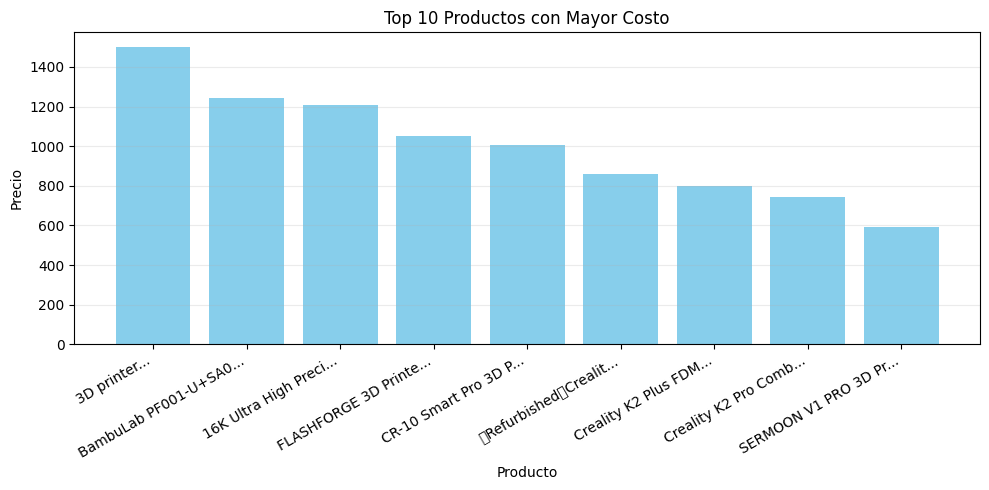

seller_name
creality-official-store    3777.17
creality_refurbished       3676.00
pcarena-bristol            3504.37
flashforge_3d_pro          2116.00
anycubic_outlet_us         1950.55
eurowagensltd1             1876.54
rapidwarehouse-office      1621.08
kelseynormand              1500.00
flashforge_3d_world        1262.00
minttooth                  1208.99
Name: price.value, dtype: float64


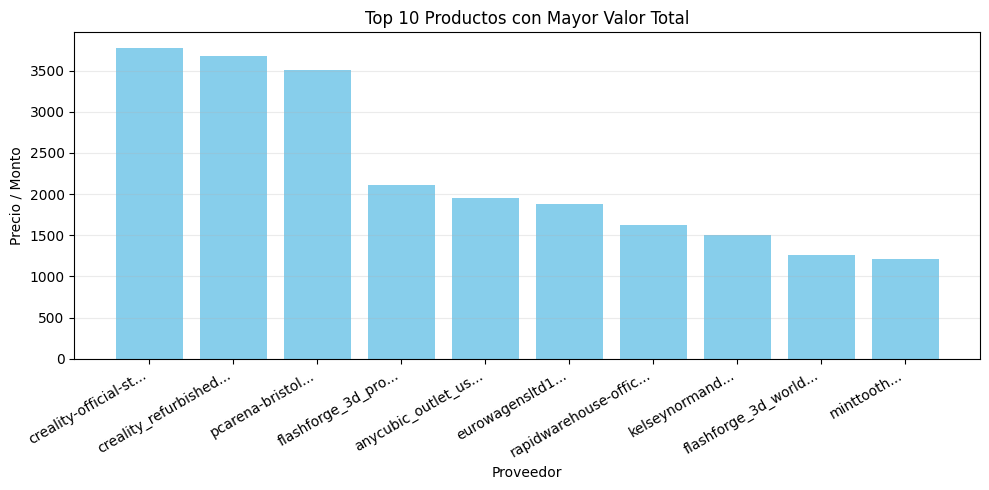

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import polars as pl


df = pd.read_csv("data_clean.csv")

precios = df['price.value'].to_numpy()
feedback_scores = df['seller_feedback_score'].to_numpy()
posiciones = df['position'].to_numpy()

# Operaciones directas con NumPy
precio_medio = np.mean(precios)
precio_std = np.std(precios)

print(f'Precio promedio: {precio_medio:.2f} (Desviación: {precio_std:.2f})')


# Filtrar productos que sean subasta (is_auction == True) y cuyo precio sea menor al promedio
condicion_subasta = df['is_auction'] & (df['price.value'] < precio_medio)
productos_filtrados = df[condicion_subasta]

print(f'Se encontraron {len(productos_filtrados)} productos en subasta baratos.')
print(productos_filtrados)



